# Phân tích Hiệu quả Chiến dịch Marketing
## Case 7 — Testing Marketing Promotions
---


In [53]:
import random

# set seed
random.seed(742)

# generate random number from 1 to 10
num = random.randint(1, 10)

print(num)

7


In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error
from scipy.stats import f_oneway, ttest_ind
from scipy import stats
from numpy.linalg import inv
import warnings
warnings.filterwarnings('ignore')

PROMO_COLORS  = ['#0066CC', '#E63946', '#2DC653']   # Promotion 1, 2, 3
MARKET_COLORS = ['#9B59B6', '#0099FF', '#FF8C00']   # Small, Medium, Large
BG = '#F9F9F9'

plt.rcParams.update({
    'figure.dpi': 130,
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.facecolor': BG,
})


---
## Bước 1 — Tải và khám phá dữ liệu


In [36]:
file_path = 'WA_Fn-UseC_-Marketing-Campaign-Eff-UseC_-FastF.csv'
df = pd.read_csv(file_path)

print(f'Dataset shape  : {df.shape}')
print(f'Missing values : {df.isnull().sum().sum()}')
print(f'Cua hang doc lap: {df["LocationID"].nunique()}')
print(f'Tuan quan sat  : {df["week"].min()} - {df["week"].max()}')
display(df.head())
display(df.describe().round(2))


Dataset shape  : (548, 7)
Missing values : 0
Cua hang doc lap: 137
Tuan quan sat  : 1 - 4


,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands
0,1,Medium,1,4,3,1,33.73
1,1,Medium,1,4,3,2,35.67
2,1,Medium,1,4,3,3,29.03
3,1,Medium,1,4,3,4,39.25
4,1,Medium,2,5,2,1,27.81


,MarketID,LocationID,AgeOfStore,Promotion,week,SalesInThousands
count,548.00,548.00,548.00,548.00,548.00,548.00
mean,5.72,479.66,8.50,2.03,2.50,53.47
std,2.88,287.97,6.64,0.81,1.12,16.76
min,1.00,1.00,1.00,1.00,1.00,17.34
25%,3.00,216.00,4.00,1.00,1.75,42.54
50%,6.00,504.00,7.00,2.00,2.50,50.20
75%,8.00,708.00,12.00,3.00,3.25,60.48
max,10.00,920.00,28.00,3.00,4.00,99.65


---
## Bước 2 — Xử lý dữ liệu (Dummy Variables)


In [37]:
df_processed = df.copy()

# Promotion: Promo_1 = base group
promotion_dummies = pd.get_dummies(
    df_processed['Promotion'], prefix='Promo', drop_first=True
).astype(int)
df_processed = pd.concat([df_processed, promotion_dummies], axis=1)

# MarketSize: Small = base group
marketsize_all = pd.get_dummies(
    df_processed['MarketSize'], prefix='Market'
).astype(int)
marketsize_dummies = marketsize_all.drop('Market_Small', axis=1)
df_processed = pd.concat([df_processed, marketsize_dummies], axis=1)

feature_cols = ['Promo_2', 'Promo_3', 'AgeOfStore', 'Market_Medium', 'Market_Large']
print(f'Base group Promotion : Promo_1')
print(f'Base group Market    : Small')
print(f'Dataset sau ma hoa   : {df_processed.shape}')


Base group Promotion : Promo_1
Base group Market    : Small
Dataset sau ma hoa   : (548, 11)


---
## Bước 3 — Trực quan hóa dữ liệu (EDA)


### Hình 1 — Boxplot và Bar chart so sánh doanh số theo Promotion


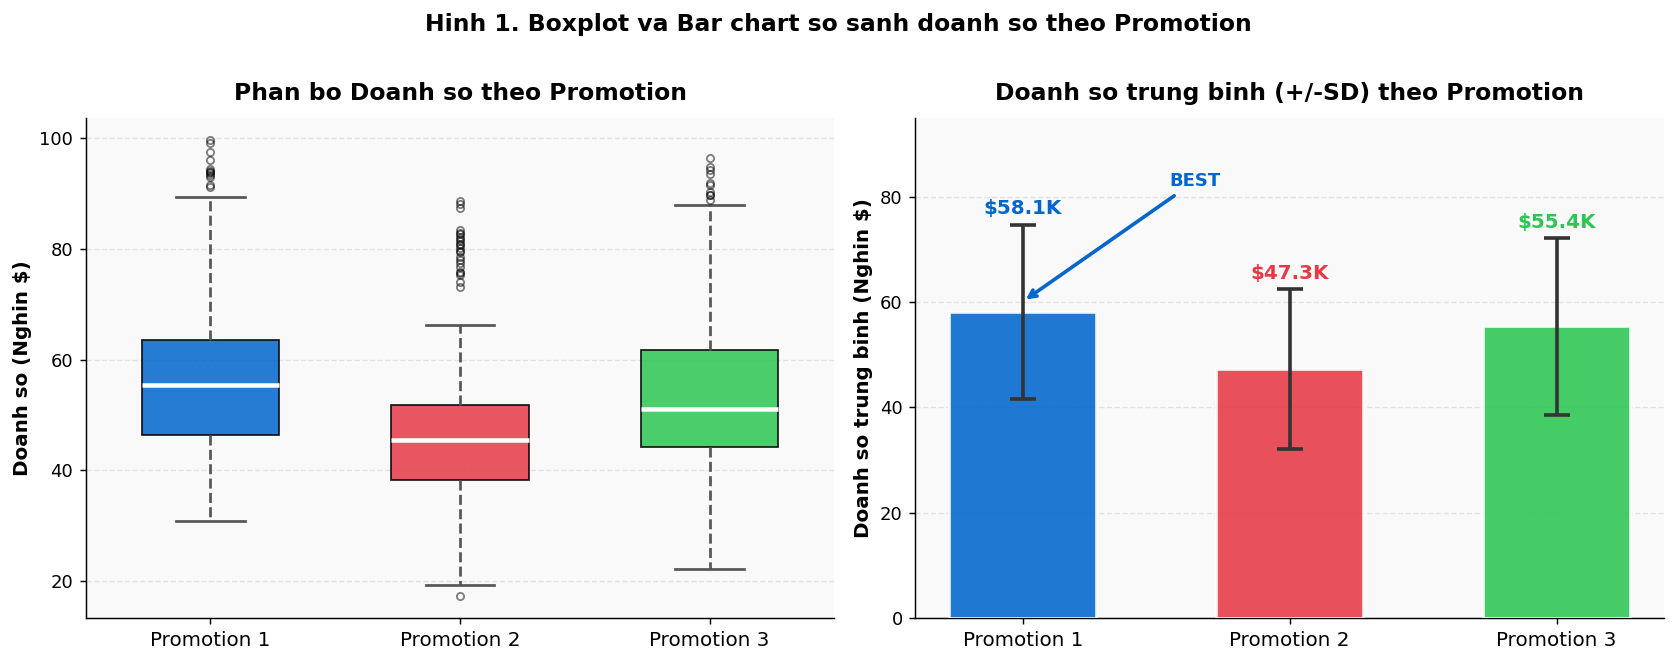

In [38]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), facecolor='white')

# Boxplot
bp = ax1.boxplot(
    [df[df.Promotion == p]['SalesInThousands'] for p in [1, 2, 3]],
    patch_artist=True, widths=0.55,
    medianprops=dict(color='white', linewidth=2.5),
    whiskerprops=dict(color='#555', linewidth=1.5, linestyle='--'),
    capprops=dict(color='#555', linewidth=1.5),
    flierprops=dict(marker='o', color='#888', alpha=0.5, markersize=4),
)
for patch, color in zip(bp['boxes'], PROMO_COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)
ax1.set_xticklabels(['Promotion 1', 'Promotion 2', 'Promotion 3'], fontsize=11)
ax1.set_ylabel('Doanh so (Nghin $)', fontsize=11, fontweight='bold')
ax1.set_title('Phan bo Doanh so theo Promotion', fontsize=13, fontweight='bold', pad=10)
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# Bar + error bars
promo_avg = df.groupby('Promotion')['SalesInThousands'].mean()
promo_std = df.groupby('Promotion')['SalesInThousands'].std()
ax2.bar([1, 2, 3], promo_avg, color=PROMO_COLORS, alpha=0.88,
        edgecolor='white', linewidth=1.5, width=0.55, zorder=3)
ax2.errorbar([1, 2, 3], promo_avg, yerr=promo_std,
             fmt='none', color='#333', capsize=7, capthick=2, linewidth=2, zorder=4)
for idx, v, std, c in zip([1, 2, 3], promo_avg, promo_std, PROMO_COLORS):
    ax2.text(idx, v + std + 2, f'${v:.1f}K',
             ha='center', fontweight='bold', fontsize=11, color=c)
ax2.annotate('BEST', xy=(1, promo_avg[1] + 2), xytext=(1.55, 82),
             arrowprops=dict(arrowstyle='->', color='#0066CC', lw=2),
             fontsize=10, fontweight='bold', color='#0066CC')
ax2.set_xticks([1, 2, 3])
ax2.set_xticklabels(['Promotion 1', 'Promotion 2', 'Promotion 3'], fontsize=11)
ax2.set_ylabel('Doanh so trung binh (Nghin $)', fontsize=11, fontweight='bold')
ax2.set_title('Doanh so trung binh (+/-SD) theo Promotion', fontsize=13, fontweight='bold', pad=10)
ax2.set_ylim(0, 95)
ax2.grid(axis='y', alpha=0.3, linestyle='--', zorder=0)

fig.suptitle('Hinh 1. Boxplot va Bar chart so sanh doanh so theo Promotion',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


### Hình 2 — Histogram phân bố doanh số của từng Promotion


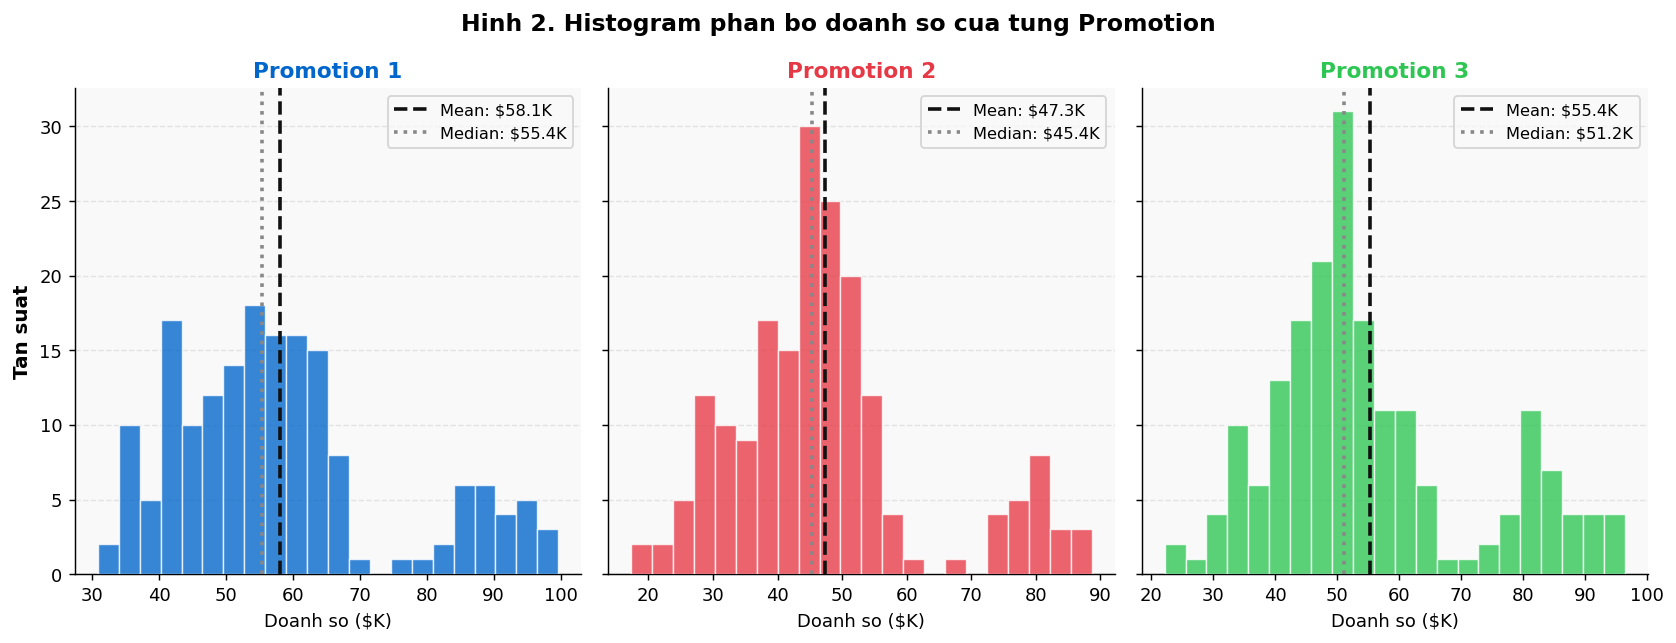

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5), sharey=True, facecolor='white')
for ax, promo, color in zip(axes, [1, 2, 3], PROMO_COLORS):
    data = df[df.Promotion == promo]['SalesInThousands']
    ax.hist(data, bins=22, color=color, alpha=0.78,
            edgecolor='white', linewidth=0.8, zorder=3)
    ax.axvline(data.mean(), color='#111', linestyle='--', linewidth=2,
               label=f'Mean: ${data.mean():.1f}K', zorder=4)
    ax.axvline(data.median(), color='#888', linestyle=':', linewidth=2,
               label=f'Median: ${data.median():.1f}K', zorder=4)
    ax.set_title(f'Promotion {promo}', fontsize=12,
                 fontweight='bold', color=color)
    ax.set_xlabel('Doanh so ($K)', fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.3, linestyle='--', zorder=0)
axes[0].set_ylabel('Tan suat', fontsize=11, fontweight='bold')
fig.suptitle('Hinh 2. Histogram phan bo doanh so cua tung Promotion',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### Hình 3 — Heatmap doanh số trung bình theo Market Size × Promotion


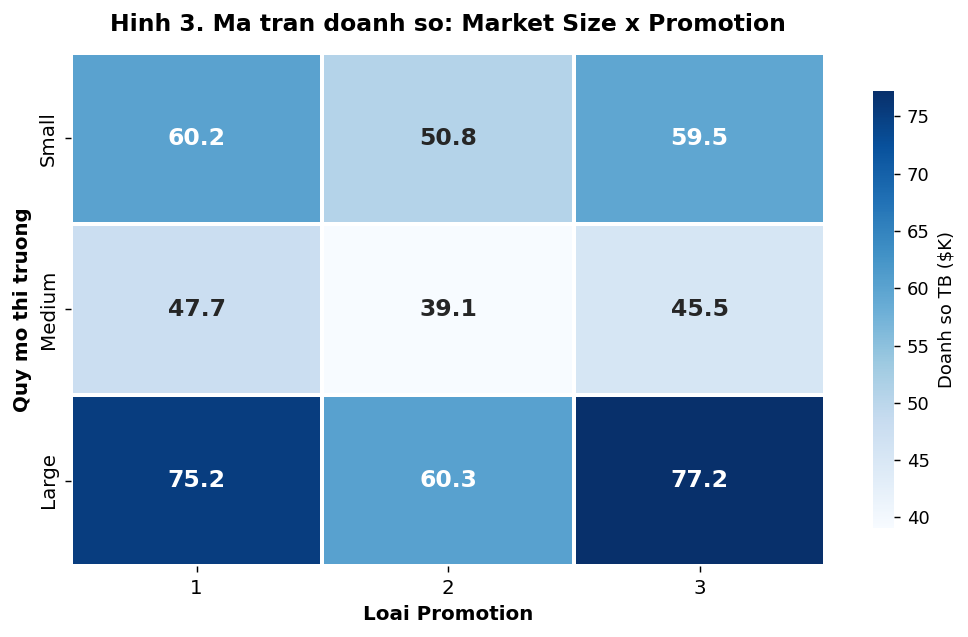

In [40]:
fig, ax = plt.subplots(figsize=(8, 5), facecolor='white')
pivot = (df.pivot_table('SalesInThousands', 'MarketSize', 'Promotion', aggfunc='mean')
           .reindex(['Small', 'Medium', 'Large']))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='Blues', ax=ax,
            cbar_kws={'label': 'Doanh so TB ($K)', 'shrink': 0.85},
            linewidths=2, linecolor='white',
            annot_kws={'fontsize': 13, 'fontweight': 'bold'})
ax.set_title('Hinh 3. Ma tran doanh so: Market Size x Promotion',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Loai Promotion', fontsize=11, fontweight='bold')
ax.set_ylabel('Quy mo thi truong', fontsize=11, fontweight='bold')
ax.tick_params(labelsize=11)
plt.tight_layout()
plt.show()


### Hình 4 — Bar chart doanh số phân theo Quy mô thị trường và Promotion


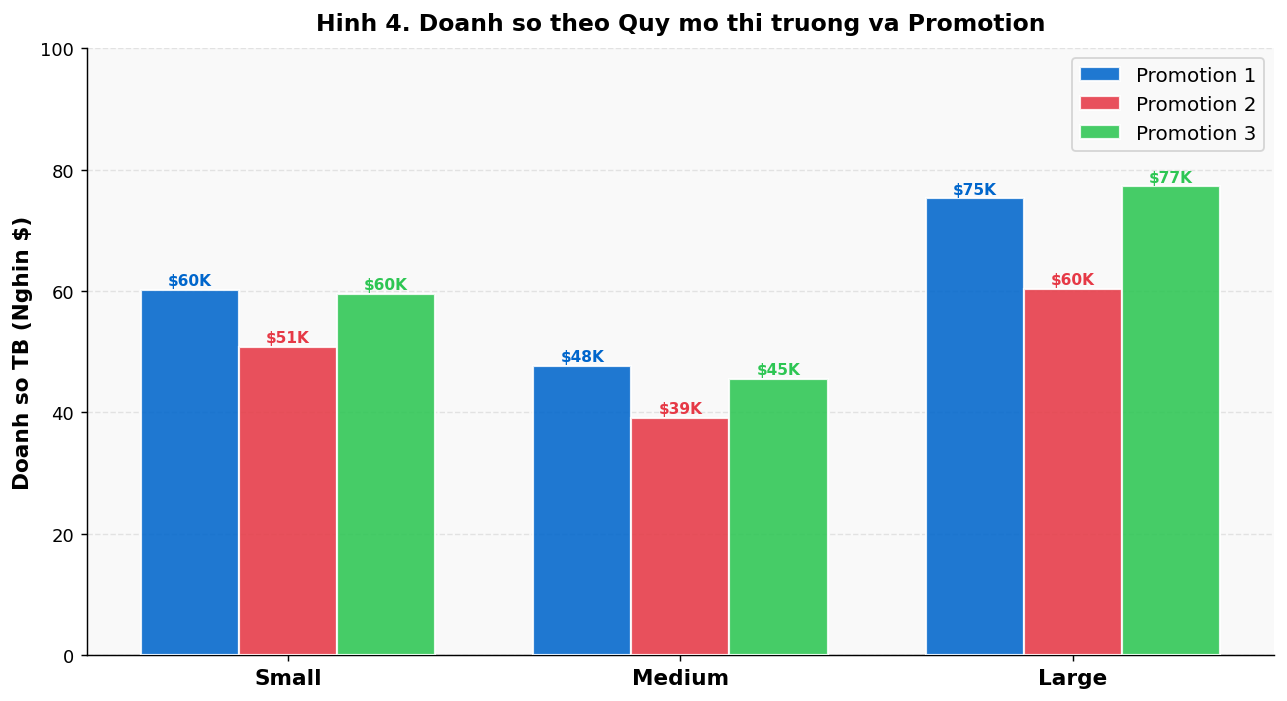

In [41]:
fig, ax = plt.subplots(figsize=(10, 5.5), facecolor='white')
markets = ['Small', 'Medium', 'Large']
x = np.arange(len(markets))
width = 0.25
for i, (promo, color) in enumerate(zip([1, 2, 3], PROMO_COLORS)):
    vals = [df[(df.MarketSize == m) & (df.Promotion == promo)]
            ['SalesInThousands'].mean() for m in markets]
    bars = ax.bar(x + (i - 1) * width, vals, width,
                  label=f'Promotion {promo}', color=color,
                  alpha=0.88, edgecolor='white', linewidth=1.2, zorder=3)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.8, f'${v:.0f}K',
                ha='center', fontsize=8.5, fontweight='bold', color=color)
ax.set_xticks(x)
ax.set_xticklabels(markets, fontsize=12, fontweight='bold')
ax.set_ylabel('Doanh so TB (Nghin $)', fontsize=12, fontweight='bold')
ax.set_title('Hinh 4. Doanh so theo Quy mo thi truong va Promotion',
             fontsize=13, fontweight='bold', pad=10)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3, linestyle='--', zorder=0)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()


### Hình 5 — Phân bố mẫu và doanh số trung bình theo Market Size


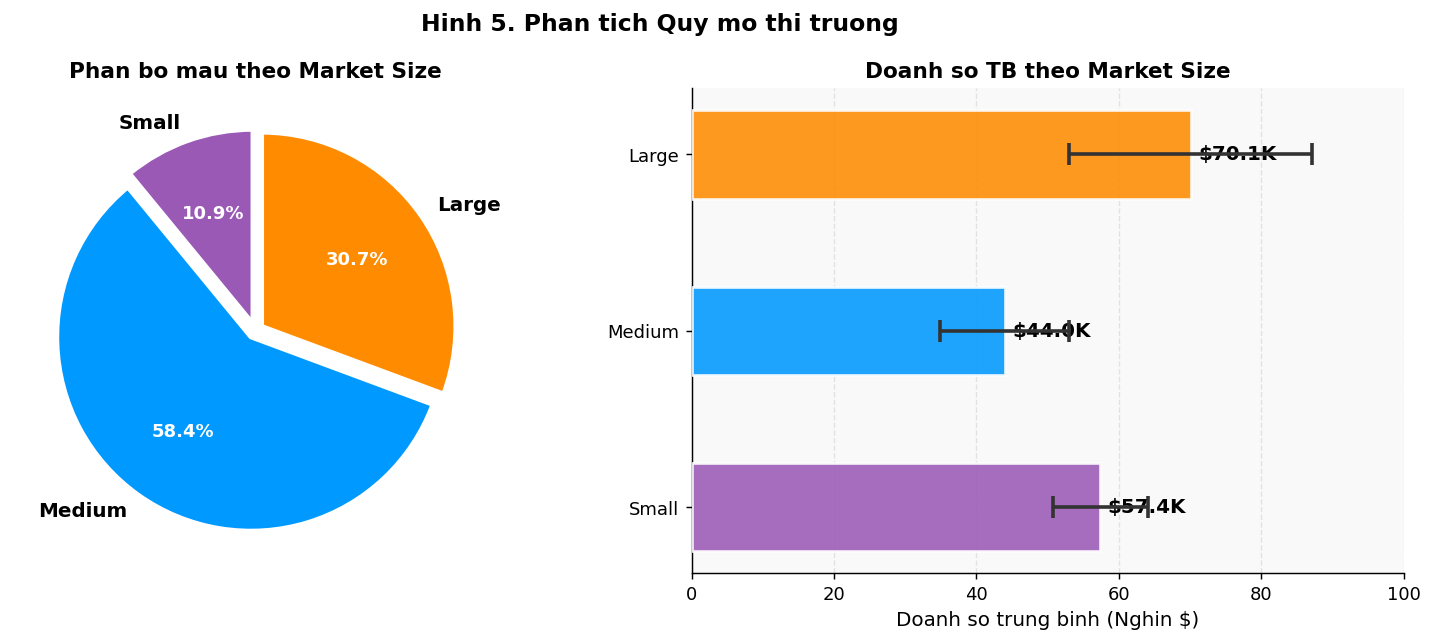

In [42]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), facecolor='white')

# Pie
market_count = df.groupby('MarketSize').size().reindex(['Small', 'Medium', 'Large'])
wedges, texts, autotexts = ax1.pie(
    market_count, labels=market_count.index, autopct='%1.1f%%',
    colors=MARKET_COLORS, startangle=90, explode=(0.04, 0.04, 0.04),
    wedgeprops={'edgecolor': 'white', 'linewidth': 2.5},
    textprops={'fontsize': 11, 'fontweight': 'bold'},
)
for at in autotexts:
    at.set_fontsize(10)
    at.set_fontweight('bold')
    at.set_color('white')
ax1.set_title('Phan bo mau theo Market Size',
              fontsize=12, fontweight='bold')

# Horizontal bar
market_avg = df.groupby('MarketSize')['SalesInThousands'].mean().reindex(['Small', 'Medium', 'Large'])
market_std = df.groupby('MarketSize')['SalesInThousands'].std().reindex(['Small', 'Medium', 'Large'])
bars = ax2.barh(['Small', 'Medium', 'Large'], market_avg,
                color=MARKET_COLORS, alpha=0.88,
                edgecolor='white', linewidth=1.5, height=0.5, zorder=3)
ax2.errorbar(market_avg, ['Small', 'Medium', 'Large'], xerr=market_std,
             fmt='none', color='#333', capsize=6, capthick=2, linewidth=2, zorder=4)
for bar, v in zip(bars, market_avg):
    ax2.text(v + 1, bar.get_y() + bar.get_height() / 2,
             f'${v:.1f}K', va='center', fontweight='bold', fontsize=11)
ax2.set_xlabel('Doanh so trung binh (Nghin $)', fontsize=11)
ax2.set_title('Doanh so TB theo Market Size',
              fontsize=12, fontweight='bold')
ax2.grid(axis='x', alpha=0.3, linestyle='--', zorder=0)
ax2.set_xlim(0, 100)

fig.suptitle('Hinh 5. Phan tich Quy mo thi truong',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### Hình 6 — Xu hướng doanh số hàng tuần theo từng Promotion


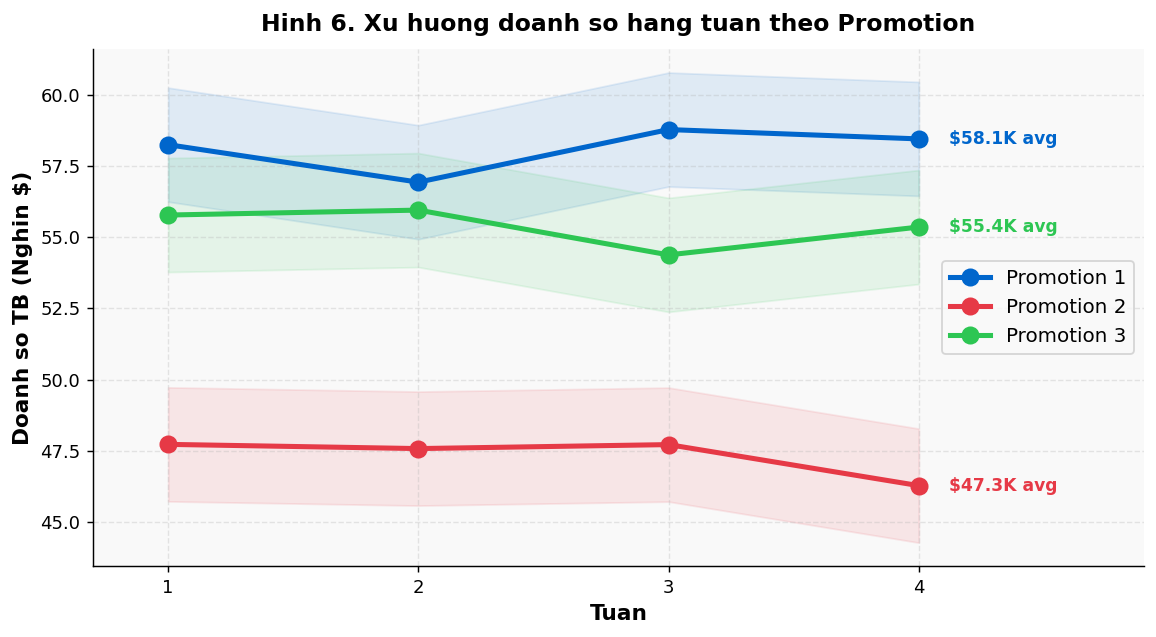

In [43]:
fig, ax = plt.subplots(figsize=(9, 5), facecolor='white')
for promo, color in zip([1, 2, 3], PROMO_COLORS):
    wd = df[df.Promotion == promo].groupby('week')['SalesInThousands'].mean()
    ax.plot(wd.index, wd.values, marker='o', label=f'Promotion {promo}',
            linewidth=2.8, markersize=9, color=color, zorder=3)
    ax.fill_between(wd.index, wd.values - 2, wd.values + 2,
                    alpha=0.10, color=color)
    ax.annotate(f'${wd.mean():.1f}K avg', xy=(4, wd.iloc[-1]),
                xytext=(4.12, wd.iloc[-1]), fontsize=9.5,
                color=color, fontweight='bold', va='center')
ax.set_xticks([1, 2, 3, 4])
ax.set_xlim(0.7, 4.9)
ax.set_xlabel('Tuan', fontsize=12, fontweight='bold')
ax.set_ylabel('Doanh so TB (Nghin $)', fontsize=12, fontweight='bold')
ax.set_title('Hinh 6. Xu huong doanh so hang tuan theo Promotion',
             fontsize=13, fontweight='bold', pad=10)
ax.legend(fontsize=11)
ax.grid(alpha=0.3, linestyle='--', zorder=0)
plt.tight_layout()
plt.show()


### Hình 7 — Scatter plot: Tuổi cửa hàng vs Doanh số


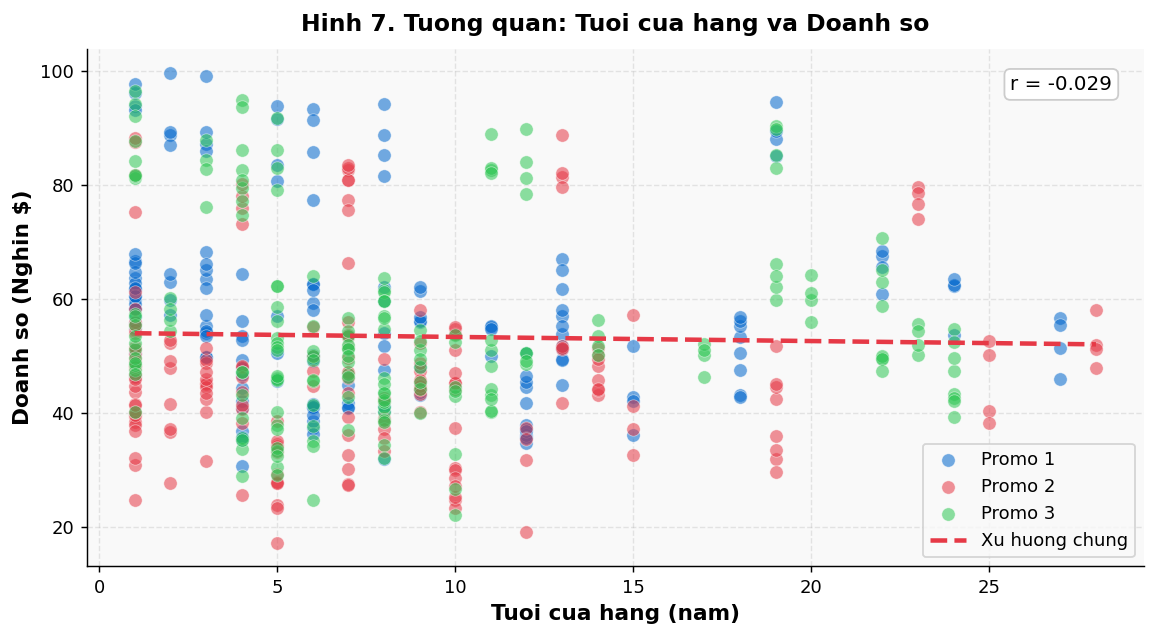

In [44]:
fig, ax = plt.subplots(figsize=(9, 5), facecolor='white')
for promo, color in zip([1, 2, 3], PROMO_COLORS):
    sub = df[df.Promotion == promo]
    ax.scatter(sub['AgeOfStore'], sub['SalesInThousands'],
               c=color, alpha=0.55, s=55, label=f'Promo {promo}',
               edgecolors='white', linewidth=0.4, zorder=3)
z = np.polyfit(df['AgeOfStore'], df['SalesInThousands'], 1)
xr = np.linspace(1, 28, 100)
ax.plot(xr, np.poly1d(z)(xr), '#E63946', linestyle='--',
        linewidth=2.5, label='Xu huong chung', zorder=4)
corr = df['AgeOfStore'].corr(df['SalesInThousands'])
ax.text(0.97, 0.95, f'r = {corr:.3f}', transform=ax.transAxes,
        ha='right', va='top', fontsize=11,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#ccc'))
ax.set_xlabel('Tuoi cua hang (nam)', fontsize=12, fontweight='bold')
ax.set_ylabel('Doanh so (Nghin $)', fontsize=12, fontweight='bold')
ax.set_title('Hinh 7. Tuong quan: Tuoi cua hang va Doanh so',
             fontsize=13, fontweight='bold', pad=10)
ax.legend(fontsize=10)
ax.grid(alpha=0.3, linestyle='--', zorder=0)
plt.tight_layout()
plt.show()


---
## Bước 4 — Kiểm định thống kê: ANOVA & T-test


In [45]:
promo1_sales = df[df['Promotion'] == 1]['SalesInThousands'].values
promo2_sales = df[df['Promotion'] == 2]['SalesInThousands'].values
promo3_sales = df[df['Promotion'] == 3]['SalesInThousands'].values

# ANOVA
f_stat, p_anova = f_oneway(promo1_sales, promo2_sales, promo3_sales)
print(f'ANOVA  F={f_stat:.4f}  p={p_anova:.6f}')
print('Ket luan: Bac bo H0 - co khac biet' if p_anova < 0.05 else 'Ket luan: Khong bac bo H0')

# T-test Bonferroni
BONFERRONI_ALPHA = 0.05 / 3
t_12, p_12 = ttest_ind(promo1_sales, promo2_sales)
t_13, p_13 = ttest_ind(promo1_sales, promo3_sales)
t_23, p_23 = ttest_ind(promo2_sales, promo3_sales)

pairs    = ['Promo 1 vs 2', 'Promo 1 vs 3', 'Promo 2 vs 3']
p_vals_t = [p_12, p_13, p_23]
t_vals   = [t_12, t_13, t_23]

print(f'\nT-test Bonferroni (alpha* = {BONFERRONI_ALPHA:.4f})')
for pair, t, p in zip(pairs, t_vals, p_vals_t):
    verdict = 'Khac biet' if p < BONFERRONI_ALPHA else 'Tuong duong'
    print(f'  {pair:<15} t={t:>7.3f}  p={p:.6f}  -> {verdict}')


ANOVA  F=21.9535  p=0.000000
Ket luan: Bac bo H0 - co khac biet

T-test Bonferroni (alpha* = 0.0167)
  Promo 1 vs 2    t=  6.454  p=0.000000  -> Khac biet
  Promo 1 vs 3    t=  1.555  p=0.120797  -> Tuong duong
  Promo 2 vs 3    t= -4.881  p=0.000002  -> Khac biet


---
## Bước 5 — OLS Regression


In [46]:
X_ols = df_processed[feature_cols].astype(float)
y_ols = df_processed['SalesInThousands'].values.astype(float)
n, k  = len(y_ols), len(feature_cols) + 1

# beta = (X'X)^-1 X'y  — sklearn khong co p-value nen tinh tay
X_np      = np.column_stack([np.ones(n), X_ols.values])
beta      = inv(X_np.T @ X_np) @ X_np.T @ y_ols
y_hat     = X_np @ beta
residuals = y_ols - y_hat
mse_resid = np.sum(residuals**2) / (n - k)
se_beta   = np.sqrt(np.diag(mse_resid * inv(X_np.T @ X_np)))
t_stats   = beta / se_beta
p_vals    = 2 * (1 - stats.t.cdf(np.abs(t_stats), df=n - k))
r2_ols    = 1 - np.sum(residuals**2) / np.sum((y_ols - y_ols.mean())**2)
rmse_ols  = np.sqrt(mse_resid)
p_vals_ols = p_vals

print(f'R2   = {r2_ols:.4f}')
print(f'RMSE = ${rmse_ols:.4f}K')
print()
col_names = ['Intercept'] + feature_cols
print(f'  {"Bien":<20} {"Coef":>10} {"Std Err":>10} {"t-stat":>10} {"p-value":>10}  Ky hieu')
print('-' * 80)
for i, col in enumerate(col_names):
    sig = ('***' if p_vals[i] < 0.001
           else '**' if p_vals[i] < 0.01
           else '*' if p_vals[i] < 0.05 else 'n.s.')
    print(f'  {col:<20} {beta[i]:>10.4f} {se_beta[i]:>10.4f}'
          f' {t_stats[i]:>10.3f} {p_vals[i]:>10.4f}  {sig}')


R2   = 0.5820
RMSE = $10.8830K

  Bien                       Coef    Std Err     t-stat    p-value  Ky hieu
--------------------------------------------------------------------------------
  Intercept               59.9407     1.7288     34.671     0.0000  ***
  Promo_2                -10.7521     1.1494     -9.355     0.0000  ***
  Promo_3                 -1.0739     1.1520     -0.932     0.3516  n.s.
  AgeOfStore               0.0709     0.0712      0.995     0.3202  n.s.
  Market_Medium          -12.5600     1.5390     -8.161     0.0000  ***
  Market_Large            14.0727     1.6611      8.472     0.0000  ***


### Hình 8 — Hệ số OLS Regression với khoảng tin cậy 95%


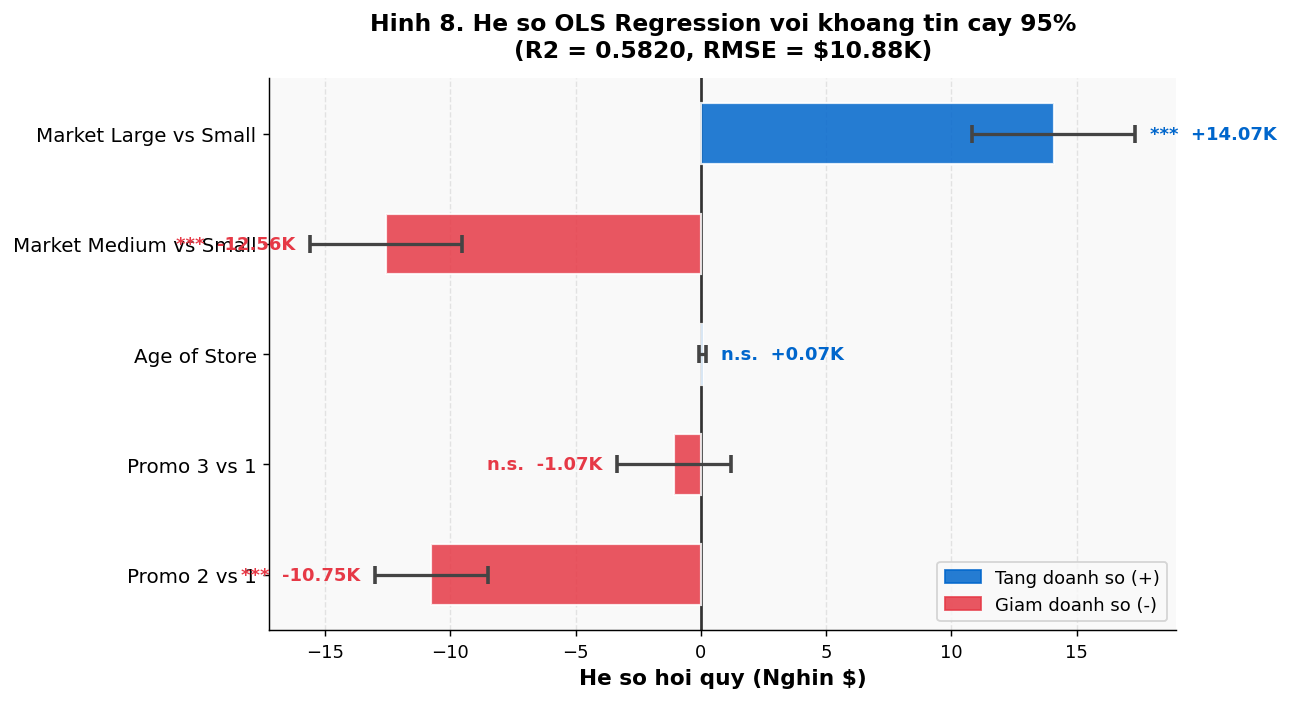

In [47]:
coefs      = beta[1:]
ses        = se_beta[1:]
labels     = ['Promo 2 vs 1', 'Promo 3 vs 1', 'Age of Store',
              'Market Medium vs Small', 'Market Large vs Small']
sig_labels = ['***' if p < 0.001 else '**' if p < 0.01
              else '*' if p < 0.05 else 'n.s.' for p in p_vals[1:]]
bar_colors = ['#0066CC' if c > 0 else '#E63946' for c in coefs]

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor='white')
y_pos = np.arange(len(labels))
ax.barh(y_pos, coefs, xerr=1.96 * ses, color=bar_colors, alpha=0.85,
        edgecolor='white', linewidth=1.2, height=0.55, zorder=3,
        error_kw=dict(ecolor='#444', capsize=5, capthick=2, linewidth=1.8))
ax.axvline(0, color='#333', linewidth=1.5, zorder=2)
for i, (c, s, sl) in enumerate(zip(coefs, ses, sig_labels)):
    xpos = c + 1.96 * ses[i] + 0.6 if c >= 0 else c - 1.96 * ses[i] - 0.6
    ha   = 'left' if c >= 0 else 'right'
    col  = '#0066CC' if c > 0 else '#E63946'
    ax.text(xpos, i, f'{sl}  {c:+.2f}K',
            va='center', ha=ha, fontsize=10, fontweight='bold', color=col)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=11)
ax.set_xlabel('He so hoi quy (Nghin $)', fontsize=12, fontweight='bold')
ax.set_title(f'Hinh 8. He so OLS Regression voi khoang tin cay 95%\n'
             f'(R2 = {r2_ols:.4f}, RMSE = ${rmse_ols:.2f}K)',
             fontsize=13, fontweight='bold', pad=12)
ax.legend(handles=[
    mpatches.Patch(color='#0066CC', alpha=0.85, label='Tang doanh so (+)'),
    mpatches.Patch(color='#E63946', alpha=0.85, label='Giam doanh so (-)'),
], fontsize=10, loc='lower right')
ax.grid(axis='x', alpha=0.3, linestyle='--', zorder=0)
plt.tight_layout()
plt.show()


---
## Bước 6 — Decision Tree


In [48]:
X_tree = df_processed[feature_cols].astype(float)
y_tree = df_processed['SalesInThousands'].values.astype(float)

tree_model = DecisionTreeRegressor(max_depth=4, min_samples_split=30, random_state=42)
tree_model.fit(X_tree, y_tree)
tree_r2    = tree_model.score(X_tree, y_tree)

importances = tree_model.feature_importances_
feat_labels = ['Promo 2', 'Promo 3', 'Age of Store', 'Market Medium', 'Market Large']
sorted_idx  = np.argsort(importances)[::-1]

print(f'Decision Tree R2 = {tree_r2:.4f}')


Decision Tree R2 = 0.6410


### Hình 9 — Feature Importance của Decision Tree


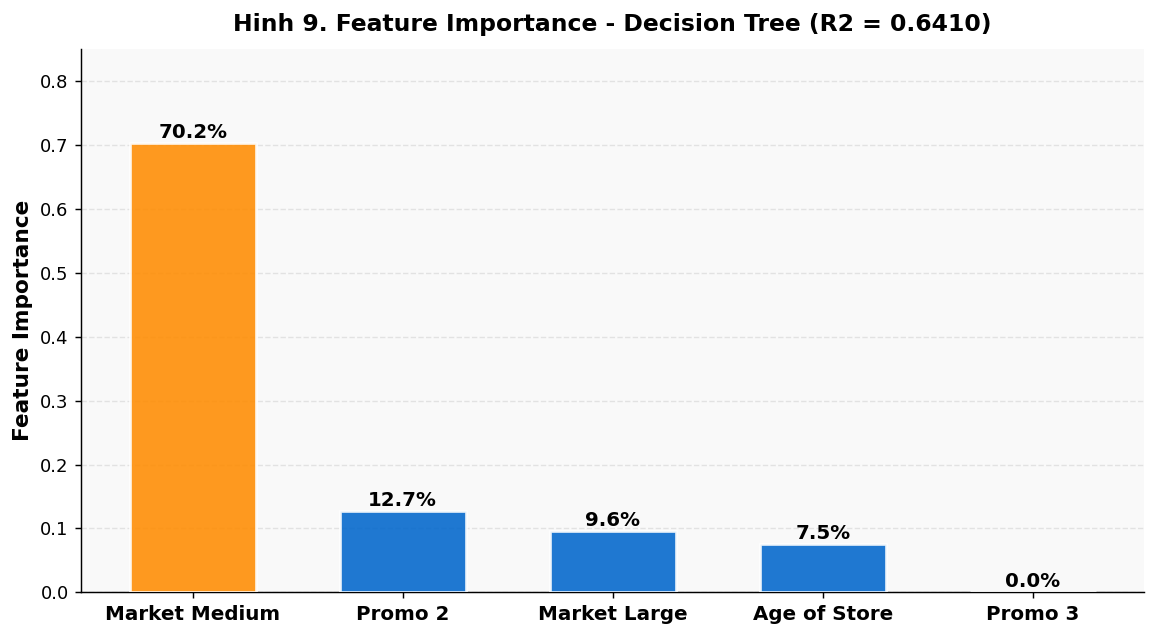

In [49]:
fig, ax = plt.subplots(figsize=(9, 5), facecolor='white')
imp_colors = ['#FF8C00' if importances[i] > 0.5
              else '#0066CC' if importances[i] > 0.05
              else '#CCCCCC' for i in sorted_idx]
ax.bar(range(5), importances[sorted_idx], color=imp_colors,
       alpha=0.88, edgecolor='white', linewidth=1.5, width=0.6, zorder=3)
ax.set_xticks(range(5))
ax.set_xticklabels([feat_labels[i] for i in sorted_idx],
                   fontsize=11, fontweight='bold')
for i, v in enumerate(importances[sorted_idx]):
    ax.text(i, v + 0.008, f'{v:.1%}',
            ha='center', fontweight='bold', fontsize=11)
ax.set_ylabel('Feature Importance', fontsize=12, fontweight='bold')
ax.set_ylim(0, 0.85)
ax.set_title(f'Hinh 9. Feature Importance - Decision Tree (R2 = {tree_r2:.4f})',
             fontsize=13, fontweight='bold', pad=10)
ax.grid(axis='y', alpha=0.3, linestyle='--', zorder=0)
plt.tight_layout()
plt.show()


### Hình 10 — Cây quyết định hoàn chỉnh (max_depth=4)


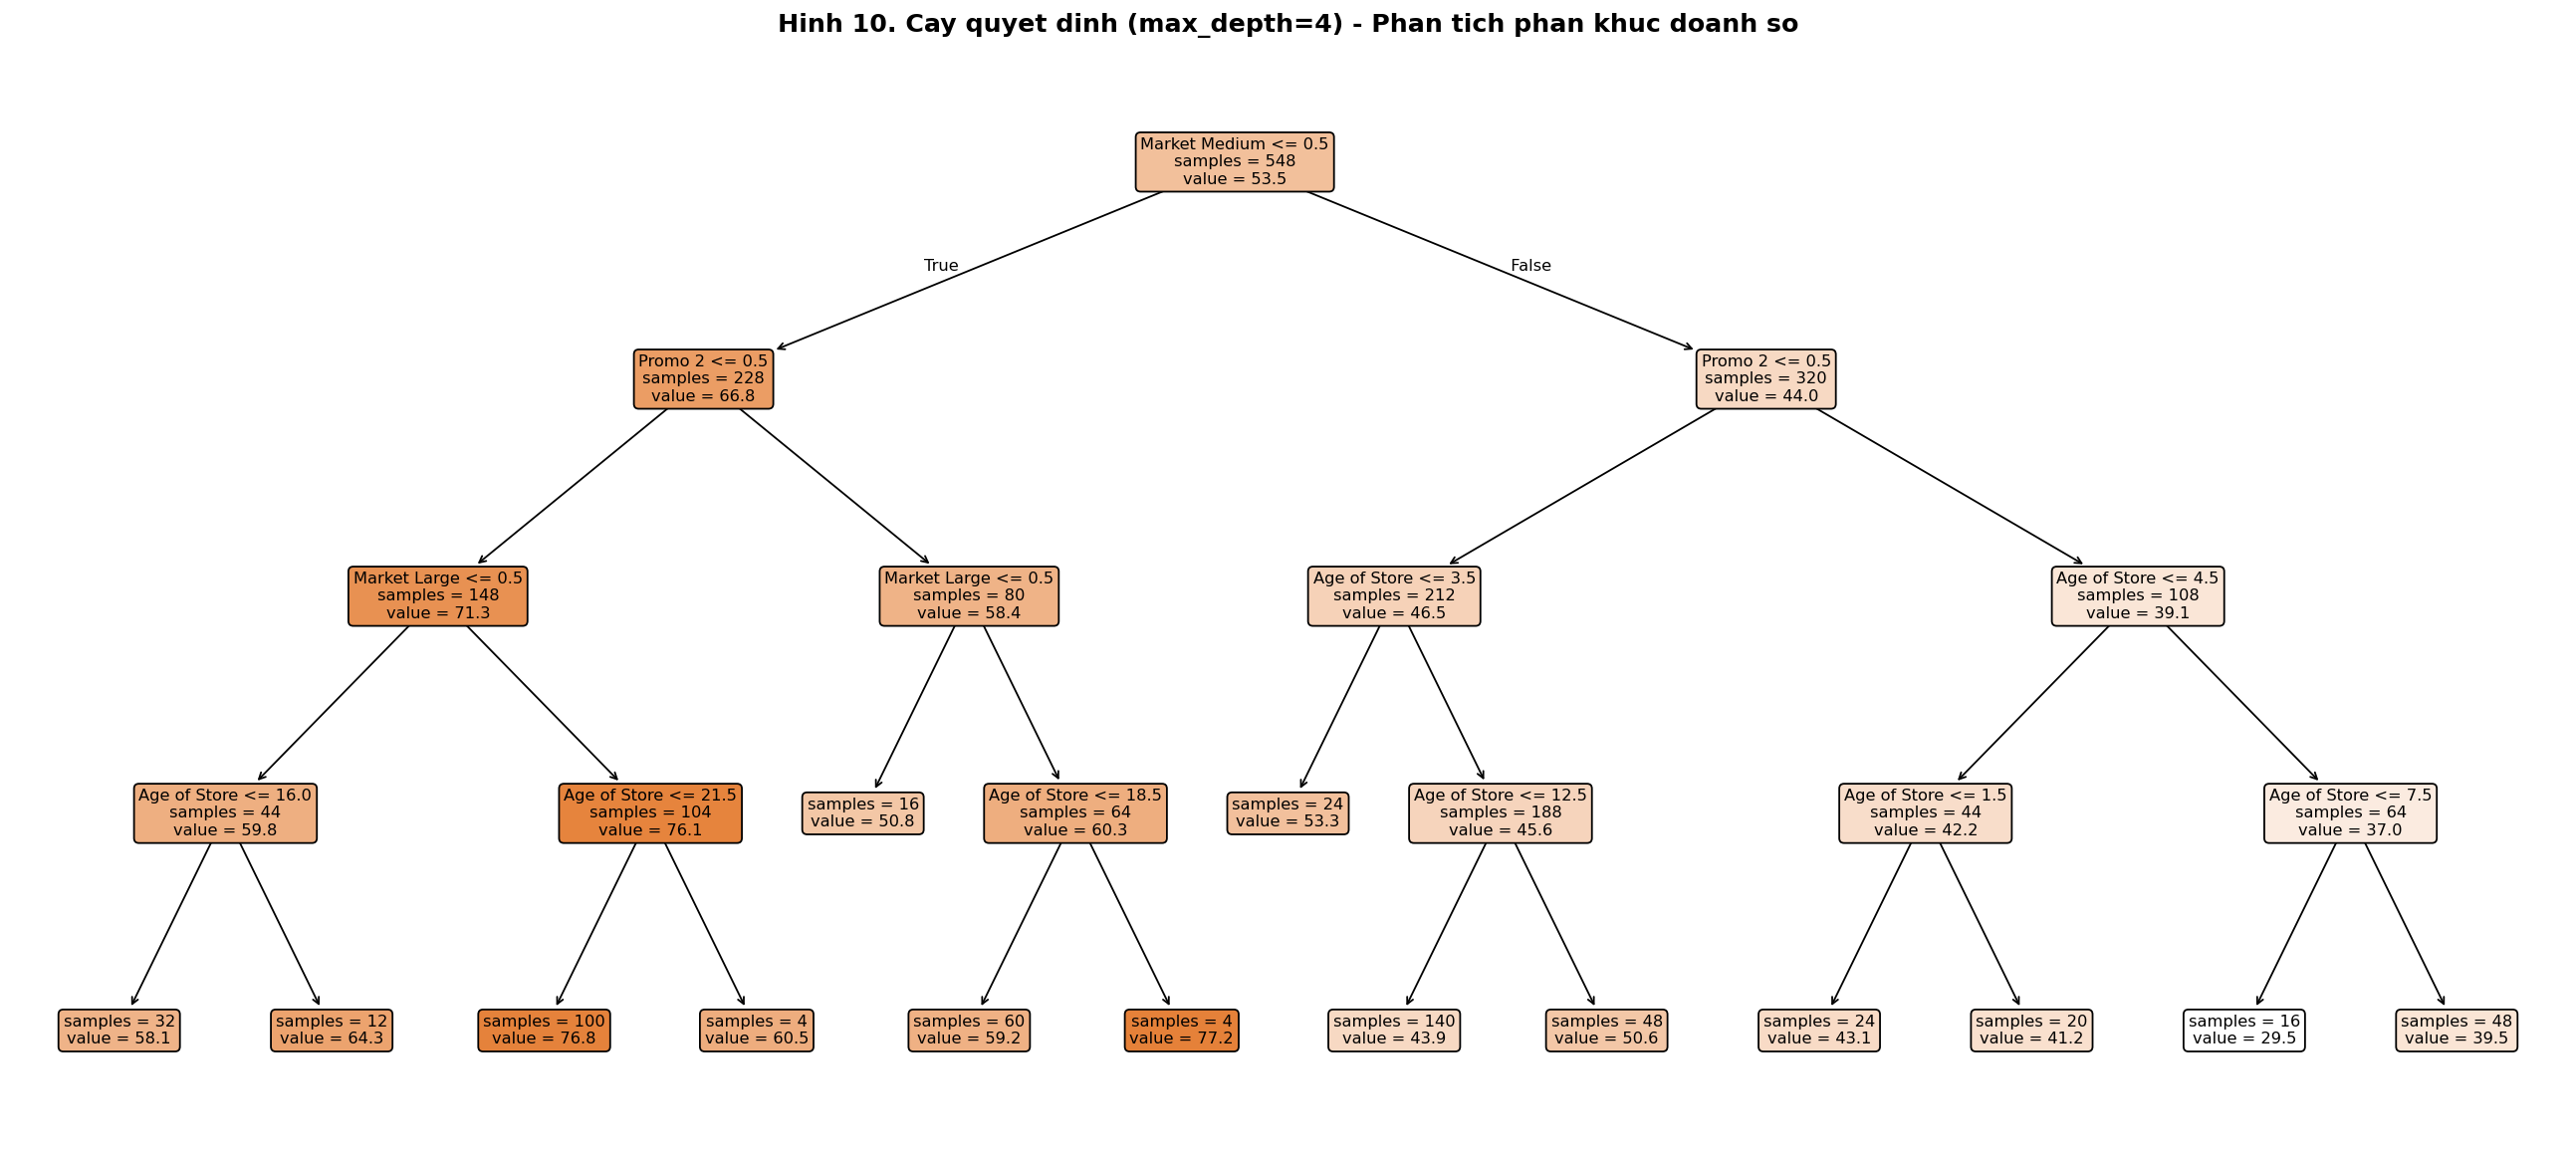

In [50]:
fig, ax = plt.subplots(figsize=(20, 9), facecolor='white')
plot_tree(tree_model,
          feature_names=feat_labels,
          filled=True, rounded=True, fontsize=9, ax=ax,
          impurity=False, precision=1)
ax.set_title('Hinh 10. Cay quyet dinh (max_depth=4) - Phan tich phan khuc doanh so',
             fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


---
## Bước 7 — Kết luận & Khuyến nghị


In [51]:
print('=' * 80)
print('KET LUAN')
print('=' * 80)
for promo in [1, 2, 3]:
    d = df[df['Promotion'] == promo]['SalesInThousands']
    print(f'  Promotion {promo}: ${d.mean():.2f}K  (n={len(d)})')
print()
print(f'  Promo 1 vs 2: +22.7%  p<0.001  ***')
print(f'  Promo 1 vs 3: +4.9%   p={p_13:.4f}  n.s. (KHONG co y nghia thong ke)')
print()
print(f'  OLS R2 = {r2_ols:.4f},  Tree R2 = {tree_r2:.4f}')
print(f'  Market_Medium importance: {importances[sorted_idx[0]]:.1%}')
print()
print('  -> CHON PROMOTION 1')
print('  -> Promo 3 tuong duong thong ke, xem xet neu chi phi thap hon')


KET LUAN
  Promotion 1: $58.10K  (n=172)
  Promotion 2: $47.33K  (n=188)
  Promotion 3: $55.36K  (n=188)

  Promo 1 vs 2: +22.7%  p<0.001  ***
  Promo 1 vs 3: +4.9%   p=0.1208  n.s. (KHONG co y nghia thong ke)

  OLS R2 = 0.5820,  Tree R2 = 0.6410
  Market_Medium importance: 70.2%

  -> CHON PROMOTION 1
  -> Promo 3 tuong duong thong ke, xem xet neu chi phi thap hon
